In [14]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20230651625
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] jpynd_evn
[学号] 20230651625
[机器指纹] 639348dc4ccdfa42
[RUN_ID] 20230651625-639348dc4ccdfa42


In [15]:

import numpy as np

int_arr = np.array([1, 2, 3, 4])
float_arr = np.array([1.5, 2.5, 3.5, 4.5])
bool_arr = np.array([True, False, True, False])

for name, arr in (("整数", int_arr), ("浮点数", float_arr), ("布尔", bool_arr)):
    print(f"{name}数组: {arr}")
    print(f"    dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")

# 差别：ndarray 的所有元素必须同类型，由 dtype 描述，内存连续、支持向量化运算；
# Python 列表可混放任意对象，没有 dtype / shape / ndim，逐个元素带类型指针，运算需循环。


整数数组: [1 2 3 4]
    dtype = int32, shape = (4,), ndim = 1
浮点数数组: [1.5 2.5 3.5 4.5]
    dtype = float64, shape = (4,), ndim = 1
布尔数组: [ True False  True False]
    dtype = bool, shape = (4,), ndim = 1


In [16]:
a = np.arange(12)
print("一维数组:", a, " shape =", a.shape)

m34 = a.reshape(3, 4)
m232 = a.reshape(2, 3, 2)
print("reshape(3, 4):\n", m34, "\nshape =", m34.shape)
print("reshape(2, 3, 2):\n", m232, "\nshape =", m232.shape)

# 改变形状只改变元素的"读法"，元素本身不变；
# 新形状各维之积必须等于原数组元素总数（这里 12），否则抛 ValueError。
try:
    a.reshape(5, 3)
except ValueError as e:
    print("reshape(5, 3) 失败:", e)


一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]  shape = (12,)
reshape(3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
shape = (3, 4)
reshape(2, 3, 2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]] 
shape = (2, 3, 2)
reshape(5, 3) 失败: cannot reshape array of size 12 into shape (5,3)


In [17]:
m = np.arange(12).reshape(3, 4)
print("矩阵 m:\n", m)

r = m[1]
print("\n第 2 行 m[1]:", r, " shape =", r.shape)

c = m[:, 0:3]
print("\n第 1~3 列 m[:, 0:3]:\n", c, "\nshape =", c.shape)

g = m[m > 6]
print("\n大于 6 的元素:", g, " shape =", g.shape)


矩阵 m:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行 m[1]: [4 5 6 7]  shape = (4,)

第 1~3 列 m[:, 0:3]:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 
shape = (3, 3)

大于 6 的元素: [ 7  8  9 10 11]  shape = (5,)


In [18]:
x = np.arange(10)
print("原数组:", x)
print("小于 2 或大于 7:", x[(x < 2) | (x > 7)],
      " | np.logical_or:", x[np.logical_or(x < 2, x > 7)])
print("大于 3 且小于 7:", x[(x > 3) & (x < 7)],
      " | np.logical_and:", x[np.logical_and(x > 3, x < 7)])


原数组: [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]  | np.logical_or: [0 1 8 9]
大于 3 且小于 7: [4 5 6]  | np.logical_and: [4 5 6]


In [19]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A:\n", A, "\nB:\n", B)
print("\nA * B:\n", A * B)
print("np.multiply(A, B):\n", np.multiply(A, B))
print("A @ B:\n", A @ B)
print("np.matmul(A, B):\n", np.matmul(A, B))

# * 与 np.multiply 是逐元素相乘（Hadamard 积），形状相同或可广播即可；
# @ 与 np.matmul 是线性代数矩阵乘法，要求 A 的列数 = B 的行数，结果是"行乘列求和"。
# 本例 A*B 得 [[5,12],[21,32]]，A@B 得 [[19,22],[43,50]]，可直观看出两种运算完全不同。


A:
 [[1 2]
 [3 4]] 
B:
 [[5 6]
 [7 8]]

A * B:
 [[ 5 12]
 [21 32]]
np.multiply(A, B):
 [[ 5 12]
 [21 32]]
A @ B:
 [[19 22]
 [43 50]]
np.matmul(A, B):
 [[19 22]
 [43 50]]


In [20]:
rng = np.random.default_rng(42)          # 固定随机种子
scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)         # 限制在 0~100

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())


样本数: 1000
最小值: 33.51587174785217
最大值: 100.0
均值: 69.70929595324685
标准差: 9.881580939490172
极差: 66.48412825214783


In [21]:
rng = np.random.default_rng(42)
pool = np.arange(1, 11)

uniform = rng.choice(pool, size=5, replace=False)          # 均匀：每个数概率 1/10
p = pool / pool.sum()                                      # 加权：概率与数值成正比
weighted = rng.choice(pool, size=5, replace=False, p=p)

print("均匀抽样(不加 p):", uniform)
print("加权抽样(p = pool / sum):", weighted)


均匀抽样(不加 p): [6 4 8 1 5]
加权抽样(p = pool / sum): [10  9  4  7  5]


In [22]:
rng = np.random.default_rng(42)

a = np.arange(10)
print("原数组 a:", a)
perm = rng.permutation(a)          # 返回打乱后的新数组，原数组不变
print("rng.permutation(a) =", perm)
print("之后 a 仍为:", a)

b = np.arange(10)
print("\n打乱前 b:", b)
rng.shuffle(b)                     # 原地打乱，直接改 b，无返回值
print("shuffle(b) 之后 b:", b)


原数组 a: [0 1 2 3 4 5 6 7 8 9]
rng.permutation(a) = [5 6 0 7 3 2 4 9 1 8]
之后 a 仍为: [0 1 2 3 4 5 6 7 8 9]

打乱前 b: [0 1 2 3 4 5 6 7 8 9]
shuffle(b) 之后 b: [4 8 2 6 5 9 7 3 0 1]


In [23]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan        # 第 10、20、30 个值设为缺失

print("普通均值 mean():", scores_nan.mean())
print("np.nanmean():", np.nanmean(scores_nan))
print("缺失值个数:", int(np.isnan(scores_nan).sum()))

# nan 参与任何算术运算结果都是 nan，所以 mean() 被"污染"成 nan；
# 必须用 nanmean / nanstd 等忽略缺失的函数，或用 ~np.isnan() 先过滤。


普通均值 mean(): nan
np.nanmean(): 69.71315691233939
缺失值个数: 3


In [24]:
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})
print(score_table.head(8))
print("行数:", len(score_table), " 缺失值:", int(score_table["成绩"].isna().sum()))
# 只存在于内存变量 score_table 中，未写磁盘，供实验 4 直接使用。


   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
5   6  56.978205
6   7  71.278404
7   8  66.837574
行数: 1000  缺失值: 3


In [25]:
import scipy.linalg

# 3x + y = 9,  x + 2y = 8
A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])

sol = scipy.linalg.solve(A, b)
print("解 [x, y]:", sol)
print("代入验证 A @ sol =", A @ sol, " 目标 b =", b)
print("完全一致:", np.allclose(A @ sol, b))


解 [x, y]: [2. 3.]
代入验证 A @ sol = [9. 8.]  目标 b = [9. 8.]
完全一致: True


In [26]:
import scipy.optimize

f = lambda t: t ** 2 - 2
pos = scipy.optimize.root(f, x0=1.0)     # 正根用正初值
neg = scipy.optimize.root(f, x0=-1.0)    # 负根用负初值

print("正根: x =", pos.x[0], " success =", pos.success, " f(x) =", f(pos.x[0]))
print("负根: x =", neg.x[0], " success =", neg.success, " f(x) =", f(neg.x[0]))
print("理论值 ±sqrt(2) =", np.sqrt(2))


正根: x = 1.4142135623730947  success = True  f(x) = -8.881784197001252e-16
负根: x = -1.4142135623730947  success = True  f(x) = -8.881784197001252e-16
理论值 ±sqrt(2) = 1.4142135623730951


In [27]:
g = lambda t: t ** 2 + 2 * t + 2
res = scipy.optimize.minimize(g, x0=0.0)

print("极小点 x =", res.x[0], " 最小值 f =", res.fun, " success =", res.success)
print("解析解：g'(x) = 2x + 2 = 0 → x = -1，f(-1) = 1，与数值结果一致")


极小点 x = -1.00000000944232  最小值 f = 1.0  success = True
解析解：g'(x) = 2x + 2 = 0 → x = -1，f(-1) = 1，与数值结果一致


In [28]:
import scipy.stats

rng = np.random.default_rng(0)                      # 固定随机种子
s1 = rng.normal(loc=0, scale=1, size=100)
s2 = rng.normal(loc=1, scale=1, size=100)

t_stat, p_val = scipy.stats.ttest_ind(s1, s2)
print(f"t 统计量 = {t_stat:.4f}, p 值 = {p_val:.4g}")
print("判断:", "p < 0.05，拒绝原假设，两组均值差异显著"
      if p_val < 0.05 else "p >= 0.05，不能拒绝原假设，差异不显著")


t 统计量 = -6.3710, p 值 = 1.288e-09
判断: p < 0.05，拒绝原假设，两组均值差异显著


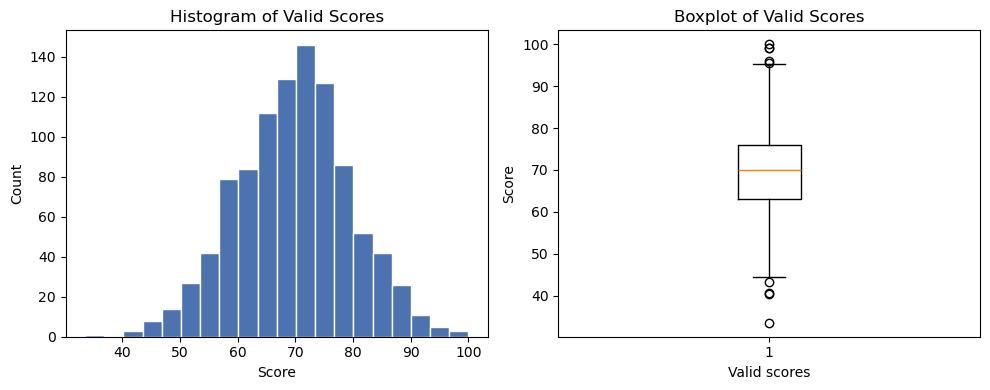

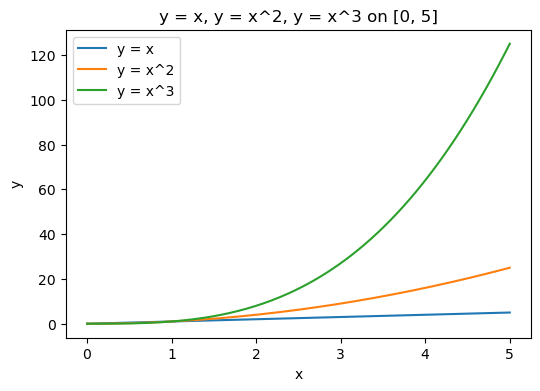

In [29]:
import matplotlib.pyplot as plt

valid = scores_nan[~np.isnan(scores_nan)]           # 实验 2 的有效成绩

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(valid, bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("Histogram of Valid Scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Count")

axes[1].boxplot(valid)
axes[1].set_title("Boxplot of Valid Scores")
axes[1].set_xlabel("Valid scores")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

xs = np.linspace(0, 5, 200)
plt.figure(figsize=(6, 4))
plt.plot(xs, xs, label="y = x")
plt.plot(xs, xs ** 2, label="y = x^2")
plt.plot(xs, xs ** 3, label="y = x^3")
plt.title("y = x, y = x^2, y = x^3 on [0, 5]")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


In [30]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")        # 行索引为姓名
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", list(df.index))
print("列名:", list(df.columns))
print("\n前 3 行:\n", df.head(3))
print("\n基本统计信息:\n", df.describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [31]:
print("loc['Carol']:\n", df.loc["Carol"])      # 按标签取
print("\niloc[2]:\n", df.iloc[2])              # 按位置取
print("\n平均分 >= 80 的学生:\n", df[df["Average"] >= 80])


loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 >= 80 的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [32]:
subjects = ["Math", "English", "Python"]

print("列均值 mean(axis=0):\n", df[subjects].mean(axis=0))
print("\n行均值 mean(axis=1):\n", df[subjects].mean(axis=1))


列均值 mean(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

行均值 mean(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [33]:
df["Max"] = df[subjects].apply(np.max, axis=1)     # 每人三科最高分
print("每人三科最高分:\n", df[["Max"]])

print("\n每科 min / mean / max:\n", df[subjects].agg(["min", "mean", "max"]))

print("\n按 Python 成绩排名 (1 为最高):\n",
      df["Python"].rank(ascending=False, method="min"))


每人三科最高分:
        Max
Name      
Alice   95
Bob     80
Carol   91
David   73
Eva     92
Frank   84

每科 min / mean / max:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按 Python 成绩排名 (1 为最高):
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


In [34]:
grouped = df.groupby("Group")

print("每组人数:\n", grouped.size())
print("\n每组三科平均分:\n", grouped[subjects].mean())

df["GroupPythonMean"] = grouped["Python"].transform("mean")
print("\n每行所在组的 Python 平均分:\n",
      df[["Group", "Python", "GroupPythonMean"]])


每组人数:
 Group
A    3
B    3
dtype: int64

每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

每行所在组的 Python 平均分:
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [35]:
kept = grouped.filter(lambda sub: sub["Python"].mean() >= 80)
print("保留的组:", sorted(kept["Group"].unique()))
print("\n保留的学生:\n", kept[["Group", "Math", "English", "Python"]])
# 实测：A 组 Python 均值 87.00、B 组 80.33，两组都 ≥ 80，所以 6 人全部保留。
# 这是数据算出来的正确结果，别以为是漏写筛选条件。


保留的组: ['A', 'B']

保留的学生:
       Group  Math  English  Python
Name                              
Alice     A    88       90      95
Bob       A    72       68      80
Carol     B    91       85      89
David     B    65       73      70
Eva       A    79       92      86
Frank     B    84       77      82


In [36]:
cov_mx = df[subjects].cov()
corr_mx = df[subjects].corr()
print("协方差矩阵:\n", cov_mx)
print("\n皮尔逊相关系数矩阵:\n", corr_mx)

# 以 Math 与 English 为例：cov = 62.567 > 0，说明两科同向变化（数学高的英语也偏高）；
# r = 0.654，属于中等偏强的正线性相关（越接近 1 越强、接近 0 表示线性关系弱）。


协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
